# Assignment 3 · Part 3 — A large language model with QLoRA
## Predicting failed public-procurement contracts in Kazakhstan

**Author:** Aziz Abdulin · **Project:** Tender Risk ML · **Repository:** https://github.com/awzwz/tender-risk-ml

Notebooks 04–05 used models built for tables (gradient boosting) and a small text encoder. This notebook tests a
different kind of model: a **1.5-billion-parameter language model** (Qwen2.5-1.5B) that reads a short Russian
description of the procurement — the same facts the boosting model gets, plus the lot names — and is adapted to the
task with **QLoRA** (low-rank adapters on a 4-bit quantised model).

| § | Content |
|---|---|
| 1 | Why an LLM, and what exactly it is trained to do |
| 2 | The input: procurement cards |
| 3 | Configuration: LoRA / QLoRA parameters, trainable parameters, why PEFT and not full fine-tuning |
| 4 | Running on Kaggle and the training log |
| 5 | Evaluation against a boosting model with the same information and the same training rows |
| 6 | Ensemble with the boosting model; conclusions |

**How to run.** The fine-tuning needs a CUDA GPU with ≥ 8 GB (4-bit quantisation is not available on macOS); it runs
as a Kaggle notebook pushed through the Kaggle API (≈ 3–4 hours on a free T4). Its outputs (scores and training log,
< 5 MB) are stored in `results/a3_06/`, so this notebook evaluates them without a GPU in a few minutes. To repeat
the training set `RUN_ON_KAGGLE = True` (needs a Kaggle account with phone verification and an API token).

## 1. Why an LLM, and what it is trained to do

**Question.** Gradient boosting is the standard for tables with hundreds of thousands of rows. A language model
brings two things boosting does not have: knowledge of the world from pretraining (what a "капитальный ремонт кровли"
is, which goods are standard) and the ability to read the lot names together with the numbers. Does that help on
this task, alone or in combination with boosting?

**Classification, not generation.** The model is not asked to write "yes / no". `AutoModelForSequenceClassification`
puts a linear layer with two outputs on the last hidden state, so the LLM outputs a **probability of failure** that
is evaluated with exactly the same metrics as every other model.

**Expectation (written before the run).** On tabular data with hundreds of thousands of rows, LLMs usually do not
beat boosting: in TabLLM (Hegselmann et al., 2023) the LLM advantage exists with few examples and disappears with
many. Here the LLM also sees no information boosting does not have. Hypothesis H8: the LLM is below boosting trained
on the full train set, close to boosting trained on the same 40 thousand rows, and adds a little in an ensemble
because it reads the text differently.

In [1]:
import json, subprocess, sys, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import lightgbm as lgb
from sklearn.decomposition import PCA
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import average_precision_score, brier_score_loss, roc_auc_score

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160); pd.set_option("display.max_colwidth", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
SEED = 42
RUN_ON_KAGGLE = False

ROOT = Path.cwd().resolve()
while not (ROOT / "src").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from src import prepare as P
from src.features import load_a3_table, REL, PRICE
from src.llm_cards import make_card

RES = ROOT / "results" / "a3_06"; RES.mkdir(parents=True, exist_ok=True)
FIG = ROOT / "figures"; PROC = ROOT / "data" / "processed"; PRED = ROOT / "data" / "predictions"
KAGGLE_DIR = ROOT / "kaggle" / "06_llm_qlora"
sns.set_theme(style="whitegrid", context="notebook")

## 2. The input: procurement cards

Each procurement becomes a short Russian paragraph with **everything the final boosting model knows**: the 20
midterm features, the customer–supplier history and the price against the market (notebook 07, `src/features.py`),
and finally the lot names. Without the numbers the comparison would be unfair to the LLM; without the lot names it
would have nothing boosting does not have in a better form. Card builder: `src/llm_cards.py`.

**Training rows.** Fine-tuning a 1.5 B model on all 266 thousand train procurements would take ≈ 10 GPU-hours. The
model is trained on **40 thousand** train procurements: 10 thousand failures and 30 thousand others (1 : 3 instead
of 1 : 14, so that the rare class is well represented). The share of failures in training only shifts the scores;
the ranking is evaluated on the real validation and test periods (all 92,495 procurements), and the probabilities
are recalibrated on validation (§5).

In [2]:
df = load_a3_table(ROOT)
cards_file = PROC / "llm_cards" / "cards.parquet"
if not cards_file.exists():
    train_all = df[df.split == "train"]
    sample = pd.concat([train_all[train_all[P.TARGET] == 1].sample(10_000, random_state=SEED),
                        train_all[train_all[P.TARGET] == 0].sample(30_000, random_state=SEED)])
    rows = pd.concat([sample, df[df.split != "train"]])
    cards_file.parent.mkdir(parents=True, exist_ok=True)
    pd.DataFrame({"id": rows.id.to_numpy(), "split": rows.split.to_numpy(),
                  "text": [make_card(r) for _, r in rows.iterrows()], "label": rows[P.TARGET].to_numpy()}).to_parquet(cards_file, index=False)
cards = pd.read_parquet(cards_file)
print(cards.groupby("split").label.agg(["size", "mean"]).rename(columns={"size": "rows", "mean": "failure share"}))
for split, label in (("test", 1), ("test", 0)):
    print(f"\n[{split}, failed={label}]", cards[(cards.split == split) & (cards.label == label)].text.iloc[0])

        rows  failure share
split                      
test   38981          0.066
train  40000          0.250
val    53514          0.069

[test, failed=1] Способ: запрос ценовых предложений. Предмет: товары. Регион: Акмолинская обл. Сумма: 2 773 000 тенге, лотов: 9. Участников: 10, заявок на лот: 2,4, лучшая цена к плановой: 82 %. Приём заявок: 10,0 дн. Закупок организатора с начала года: 57. Доля побед победителя в прошлых закупках: 23 %. Цена за единицу к рыночной: ×1,00. Лоты: Халат; Устройство ветеринарное; Коробка передач; Халат; Вата; Устройство ветеринарное; Перчатки; Спирт; Редуктор моста

[test, failed=0] Способ: запрос ценовых предложений. Предмет: товары. Регион: Северо-Казахстанская обл. Сумма: 135 527 тенге, лотов: 2. Участников: 2, заявок на лот: 2,0, лучшая цена к плановой: 71 %. Приём заявок: 10,0 дн. Закупок организатора с начала года: 43. Доля побед победителя в прошлых закупках: 24 %. Цена за единицу к рыночной: ×0,89. Лоты: Огнетушитель; Огнетушитель


In [3]:
from tokenizers import Tokenizer            # the Qwen tokenizer without loading torch
tk = Tokenizer.from_pretrained("Qwen/Qwen2.5-1.5B")
lens = pd.Series([len(e.ids) for e in tk.encode_batch(cards.text.sample(20_000, random_state=SEED).tolist())])
print("tokens per card:", lens.describe(percentiles=[0.5, 0.9, 0.99]).round(0).to_dict())
print(f"cards longer than the 224-token limit: {(lens > 224).mean():.1%} (only the end of the lot list is cut)")

tokens per card: {'count': 20000.0, 'mean': 167.0, 'std': 36.0, 'min': 91.0, '50%': 164.0, '90%': 198.0, '99%': 324.0, 'max': 399.0}
cards longer than the 224-token limit: 5.1% (only the end of the lot list is cut)


## 3. Configuration

**QLoRA in one paragraph.** The pretrained weights of Qwen2.5-1.5B are frozen and stored in 4 bits (NF4 — a 4-bit
format designed for normally distributed weights — with double quantisation of the scaling constants). Next to each
of the seven linear projections of every transformer layer, LoRA adds two small trainable matrices *A* (d_in × r) and
*B* (r × d_out); their product *BA*, scaled by α / r, is added to the frozen weight. Only *A*, *B* and the new
classification head are trained.

| Parameter | Value | Why |
|---|---|---|
| Base model | `Qwen/Qwen2.5-1.5B` | Russian is among the officially supported languages; Apache-2.0 licence; sizes 0.5–7 B with the same architecture |
| Quantisation | 4-bit NF4, double quantisation, fp16 compute | QLoRA settings of Dettmers et al. (2023); the T4 has no bf16 tensor cores |
| `r` (rank) | 16 | 8 is often too little for a new task; 64 adds memory with little gain |
| `lora_alpha` | 32 (= 2r) | scaling α / r = 2, the usual ratio |
| `lora_dropout` | 0.05 | light regularisation of the adapters |
| `target_modules` | `q_proj, k_proj, v_proj, o_proj, gate_proj, up_proj, down_proj` | adapters on all linear layers come closest to full fine-tuning (QLoRA paper) |
| Classification head | trained in full (`modules_to_save=["score"]`) | it is new, there are no pretrained weights to preserve |
| Optimiser | paged AdamW, 8-bit states | keeps optimiser memory small |
| Learning rate | 2e-4, cosine decay, 3 % warm-up | adapters need a larger step than full fine-tuning |
| Batch | 16 × 4 gradient accumulation = 64 | fits a 16 GB T4 at ≤ 224 tokens |
| Epochs | 1 | on 40 thousand rows a second epoch mostly memorises |
| Gradient clipping, loss scaling | 1.0, dynamic fp16 loss scaling | stability of fp16 training |

In [4]:
# Trainable parameters: r · (d_in + d_out) for every adapted matrix, plus the head. Qwen2.5-1.5B: 28 layers,
# hidden 1536, 12 query heads and 2 key/value heads of size 128 (k, v projections are 1536 -> 256), MLP 8960.
layers, h, kv, mlp, r = 28, 1536, 256, 8960, 16
per_layer = r * ((h + h) + (h + kv) + (h + kv) + (h + h) + (h + mlp) + (h + mlp) + (mlp + h))
head = h * 2
formula = layers * per_layer + head
measured = 18_467_840                     # printed by peft on Kaggle (see the training log below)
total = 1_543_714_304 + measured          # base weights of Qwen2.5-1.5B (without the LM head) + trainable
pd.Series({"LoRA adapters (formula)": layers * per_layer, "classification head": head, "trainable, formula": formula,
           "trainable, measured by peft": measured, "share of all parameters": f"{measured / total:.2%}"}).to_frame("value")

,value
LoRA adapters (formula),18464768
classification head,3072
"trainable, formula",18467840
"trainable, measured by peft",18467840
share of all parameters,1.18%


**Why parameter-efficient fine-tuning instead of full fine-tuning** (memory without activations):

| | Full fine-tuning of 1.5 B | QLoRA (this notebook) |
|---|---|---|
| Weights | 3.1 GB in fp16 + 6.2 GB fp32 master copy | ≈ 1.3 GB in 4 bits |
| Gradients | 3.1 GB | only for 18.5 M parameters |
| Adam states | 12.3 GB | < 0.15 GB (8-bit) |
| **Total** | **≈ 25 GB — does not fit a T4 (16 GB) or an RTX 4090 (24 GB)** | **≈ 2.7 GB peak, measured** |
| Risk of overfitting 40 k rows | high: 1.5 B free parameters | low: 1.2 % of the parameters change |
| Size of the result | 3 GB | ≈ 70 MB adapter |

The base model is also left untouched: its general knowledge of the language is not overwritten by a narrow task,
and the same 4-bit base can serve several adapters.

## 4. Running on Kaggle and the training log

The training script is `kaggle/06_llm_qlora/train_qlora.py`. The cells below upload the cards as a private Kaggle
dataset, push the script as a GPU notebook, wait for it and download the outputs — all through the Kaggle API, so the
run is reproducible from this repository. They only run when `RUN_ON_KAGGLE = True`; otherwise the stored outputs
are used.

In [5]:
def kaggle(*args):
    out = subprocess.run([str(Path(sys.executable).with_name("kaggle")), *args], capture_output=True, text=True)
    return (out.stdout + out.stderr).strip()

if RUN_ON_KAGGLE:
    print(kaggle("datasets", "version", "-p", str(cards_file.parent), "-m", "cards rebuilt"))
    print(kaggle("kernels", "push", "-p", str(KAGGLE_DIR)))
    while True:
        status = kaggle("kernels", "status", "azizabdulin/tender-risk-llm-qlora")
        if any(s in status for s in ("COMPLETE", "ERROR", "CANCEL")): break
        time.sleep(300)
    print(status)
    print(kaggle("kernels", "output", "azizabdulin/tender-risk-llm-qlora", "-p", str(RES)))
print(sorted(p.name for p in RES.iterdir()))

['adapter', 'blend_weight.json', 'llm_predictions.parquet', 'llm_vs_boosting.csv', 'tender-risk-llm-qlora.log', 'train_log.json']


GPU: Tesla T4 | rows: {'train': 40000, 'val+test': 92495, 'train failure share': 0.25} | parameters: {'trainable': 18467840, 'total (4-bit weights counted as stored)': 907087360}
training 2.19 h, inference on validation + test 1.26 h


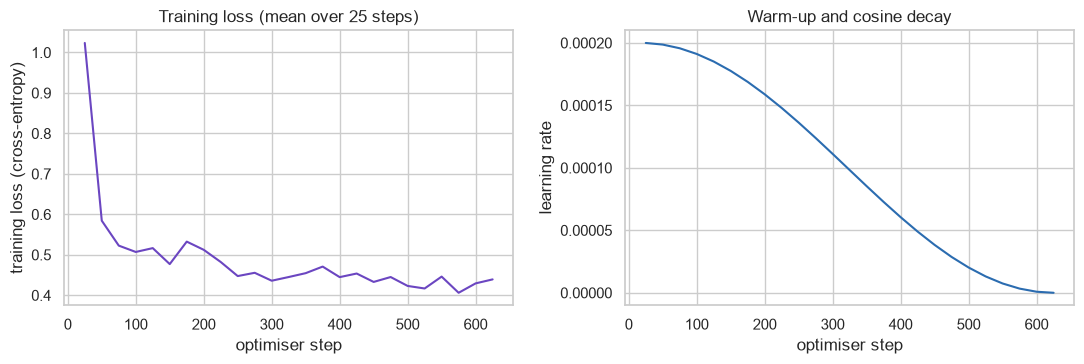

In [6]:
log = json.loads((RES / "train_log.json").read_text())
steps = pd.DataFrame(log["steps"])
print("GPU:", log["gpu"], "| rows:", log["rows"], "| parameters:", log["parameters"])
print(f"training {log['train_hours']:.2f} h, inference on validation + test {log['inference_hours']:.2f} h")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(steps.step, steps.loss, color="#6b46c1"); ax[0].set(xlabel="optimiser step", ylabel="training loss (cross-entropy)", title="Training loss (mean over 25 steps)")
ax[1].plot(steps.step, steps.lr, color="#2b6cb0"); ax[1].set(xlabel="optimiser step", ylabel="learning rate", title="Warm-up and cosine decay")
plt.tight_layout(); plt.savefig(FIG / "a3_06_training.png", dpi=150, bbox_inches="tight"); plt.show()

## 5. Evaluation

Three references, all scored on the same validation and test procurements:

* **LightGBM, same rows and same information** — trained on the *same 40 thousand* train procurements with the same
  facts as the card (20 features + history + price) and the lot text as 32 components of frozen rubert-tiny2 vectors
  (notebook 05b). If the LLM loses to this model, the method is weaker; if it wins, reading the text as language helps.
* **LightGBM, full train** — the same configuration and information on all 266 thousand train procurements. The gap
  between the two LightGBM rows shows how much the LLM is held back by its smaller training set.
* **No model** — the failure rate.

In [7]:
llm = pd.read_parquet(RES / "llm_predictions.parquet").set_index("id").score
for c in P.CAT_FEATURES: df[c] = df[c].astype("category")
df["text"] = df[P.TEXT_FEATURE].fillna("").str.lower().str.strip()
E = np.load(PROC / "emb_rubert-tiny2.npy"); texts = pd.read_parquet(PROC / "emb_texts.parquet").text
tpos = pd.Series(np.arange(len(texts)), index=texts.values)
T = [f"emb{k}" for k in range(32)]
df[T] = PCA(32, random_state=SEED).fit(E[tpos[df.loc[df.split == "train", "text"]].to_numpy()]).transform(E[tpos[df.text].to_numpy()])
COLS = P.FEATURES + T + REL + PRICE

train, val, test = (df[df.split == s].reset_index(drop=True) for s in ("train", "val", "test"))
y = P.TARGET; y_va, y_te = val[y].to_numpy(), test[y].to_numpy()
sample_ids = set(cards.loc[cards.split == "train", "id"])
# Workhorse LightGBM for feature experiments (notebook 04: tuning LightGBM brings no gain on these features, and this
# configuration is as good as the best of 50 Optuna trials on validation while being stable and fast)
LGB = dict(learning_rate=0.05)

def fit_lgb(tr):
    m = lgb.LGBMClassifier(n_estimators=5000, random_state=SEED, verbose=-1, **LGB)
    m.fit(tr[COLS], tr[y], eval_set=[(val[COLS], y_va)], eval_metric="average_precision",
          callbacks=[lgb.early_stopping(100, verbose=False)])
    return m.predict_proba(val[COLS])[:, 1], m.predict_proba(test[COLS])[:, 1]

scores = {"Qwen2.5-1.5B + QLoRA (40 k rows)": (llm.loc[val.id].to_numpy(), llm.loc[test.id].to_numpy()),
          "LightGBM, same 40 k rows, same information": fit_lgb(train[train.id.isin(sample_ids)]),
          "LightGBM, full train (266 k rows)": fit_lgb(train)}
unseen = ~test.text.isin(set(train.text)).to_numpy()
rng = np.random.default_rng(SEED); BOOT = [rng.integers(0, len(y_te), len(y_te)) for _ in range(1000)]
def boot_diff(a, b):
    d = np.array([average_precision_score(y_te[i], a[i]) - average_precision_score(y_te[i], b[i]) for i in BOOT])
    return f"{d.mean():+.3f} [{np.percentile(d, 2.5):+.3f}, {np.percentile(d, 97.5):+.3f}]"
llm_te = scores["Qwen2.5-1.5B + QLoRA (40 k rows)"][1]
rows = {}
for name, (pv, pt) in scores.items():
    rows[name] = {"val PR-AUC": average_precision_score(y_va, pv), "test PR-AUC": average_precision_score(y_te, pt),
                  "test ROC-AUC": roc_auc_score(y_te, pt),
                  "test PR-AUC, unseen texts": average_precision_score(y_te[unseen], pt[unseen]),
                  "LLM minus this model (test PR-AUC)": "" if "Qwen" in name else boot_diff(llm_te, pt)}
rows["No model"] = {"val PR-AUC": y_va.mean(), "test PR-AUC": y_te.mean(), "test ROC-AUC": 0.5,
                    "test PR-AUC, unseen texts": y_te[unseen].mean(), "LLM minus this model (test PR-AUC)": ""}
llm_table = pd.DataFrame(rows).T; llm_table

,val PR-AUC,test PR-AUC,test ROC-AUC,"test PR-AUC, unseen texts",LLM minus this model (test PR-AUC)
Qwen2.5-1.5B + QLoRA (40 k rows),0.372,0.322,0.808,0.368,
"LightGBM, same 40 k rows, same information",0.387,0.334,0.819,0.371,"-0.011 [-0.024, +0.000]"
"LightGBM, full train (266 k rows)",0.400,0.350,0.824,0.383,"-0.028 [-0.041, -0.015]"
No model,0.069,0.066,0.500,0.097,


In [8]:
# The LLM was trained with 25 % failures (real rate 6.6 %), so its raw scores are too high. Platt scaling fitted on
# validation fixes the probabilities without changing the ranking (isotonic regression, for comparison, creates ties).
from sklearn.linear_model import LogisticRegression
pv, pt = scores["Qwen2.5-1.5B + QLoRA (40 k rows)"]
lg = lambda p: np.log(np.clip(p, 1e-7, 1 - 1e-7) / (1 - np.clip(p, 1e-7, 1 - 1e-7)))
platt = LogisticRegression(C=1e6, max_iter=1000).fit(lg(pv).reshape(-1, 1), y_va).predict_proba(lg(pt).reshape(-1, 1))[:, 1]
iso = IsotonicRegression(out_of_bounds="clip").fit(pv, y_va).predict(pt)
pd.DataFrame({k: {"mean score": v.mean(), "Brier": brier_score_loss(y_te, v), "PR-AUC": average_precision_score(y_te, v)}
              for k, v in (("raw", pt), ("Platt, fitted on validation", platt), ("isotonic, fitted on validation", iso))}).T \
  .assign(**{"actual failure rate": y_te.mean()})

,mean score,Brier,PR-AUC,actual failure rate
raw,0.188,0.074,0.322,0.066
"Platt, fitted on validation",0.066,0.052,0.322,0.066
"isotonic, fitted on validation",0.066,0.052,0.308,0.066


## 6. Ensemble with the boosting model

The LLM and boosting see the same facts but process them differently (a language model reads the lot names as words
in context; boosting splits numbers). If their errors differ, averaging helps. The weight is chosen on validation
(logit scale) and applied unchanged to test.

In [9]:
logit = lambda p: np.log(np.clip(p, 1e-6, 1 - 1e-6) / (1 - np.clip(p, 1e-6, 1 - 1e-6)))
gb_va, gb_te = scores["LightGBM, full train (266 k rows)"]
w = np.linspace(0, 1, 21)
curve = [average_precision_score(y_va, (1 - a) * logit(gb_va) + a * logit(pv)) for a in w]
alpha = float(w[int(np.argmax(curve))])
blend_te = (1 - alpha) * logit(gb_te) + alpha * logit(pt)
print(f"weight of the LLM chosen on validation: {alpha:.2f}")
print(f"test PR-AUC: LightGBM {average_precision_score(y_te, gb_te):.3f} -> ensemble {average_precision_score(y_te, blend_te):.3f}; "
      f"difference {boot_diff(blend_te, gb_te)}")
pd.DataFrame({"id": np.r_[val.id, test.id], "split": ["val"] * len(val) + ["test"] * len(test),
              "score": np.r_[(1 - alpha) * logit(gb_va) + alpha * logit(pv), blend_te]}).to_parquet(PRED / "06_blend_lgb_llm.parquet", index=False)
pd.DataFrame({"id": np.r_[val.id, test.id], "split": ["val"] * len(val) + ["test"] * len(test),
              "score": np.r_[pv, pt]}).to_parquet(PRED / "06_llm_qlora.parquet", index=False)
llm_table.to_csv(RES / "llm_vs_boosting.csv"); _ = (RES / "blend_weight.json").write_text(json.dumps({"alpha": alpha}))

weight of the LLM chosen on validation: 0.35


test PR-AUC: LightGBM 0.350 -> ensemble 0.358; difference +0.008 [+0.005, +0.012]


### Conclusions

* **The LLM learns the task.** Fine-tuning 1.2 % of the parameters of Qwen2.5-1.5B for one epoch on 40 thousand
  cards (2.2 GPU-hours on a free T4) gives test PR-AUC **0.322** — above every model on the 20 midterm features
  (best: tuned CatBoost, 0.311) — and ROC-AUC 0.808.
* **As a method it is slightly weaker than boosting.** Given the same 40 thousand rows and the same information,
  LightGBM reaches 0.334: the LLM is 0.011 lower (95 % CI [−0.024, 0.000]). With all 266 thousand training rows,
  boosting reaches 0.350 and the gap grows to 0.028 [−0.041, −0.015] — part of the LLM's disadvantage is simply
  the smaller training set that GPU time allows. On procurements whose text never appeared in train the three models
  are close (0.368 / 0.371 / 0.383), so the LLM's reading of the lot names is about as good as the encoder features.
* **It sees something boosting does not.** Averaging the two (weight 0.35 on the LLM, chosen on validation) raises
  test PR-AUC from 0.350 to **0.358**, +0.008 [+0.005, +0.012]: the interval excludes zero, so the errors of the two
  models are different enough to be worth combining. This is hypothesis H8 as written before the run: below
  boosting alone, useful in an ensemble.
* **Probabilities.** Trained on a 1 : 3 sample, the raw LLM scores average 0.19 against a real failure rate of
  0.066; Platt scaling on validation fixes that without changing the ranking.